# Notebook 3 - Evaluation of the Phase 2 + 3 models, **exactly the way the paper validates**

Paper protocol (Gan et al., IEEE TAFFC 2026, Sec. V): **Leave-One-Speaker-Out (LOSO) cross-validation, 10 folds** - each fold's model is tested on the speaker it never saw. Reported: **WA** and **UA** per fold, then **mean, std and 95% CI over the folds (Table IV)**, **macro / weighted F1, precision, recall (Table V)** and a **confusion matrix (Fig. 5)**.

This notebook loads `phase3_<speaker>.pt` from Notebooks **2A-2E** and produces the same tables and figures, plus the paper's numbers next to yours for comparison.

**Class view:** all **6 classes** of your model (anger, happiness, sadness, neutral, frustration, fear). The paper itself reports 4 classes, so its numbers are shown only if you add `"paper4"` to `VIEWS` (section 11) - they are not comparable with a 6-class result.

**Inputs to attach:** (1) all-sessions preprocessed dataset, (2) Wav2Vec model dataset, (3-7) outputs of Notebook 2A, 2B, 2C, 2D, 2E. Works with fewer sessions too (the statistics then use the folds that are available).
**Outputs** (`/kaggle/working/final_eval/`): `*_table_IV*.png/csv`, `*_table_V*`, `*_table_VI*`, `*_fig1_per_fold.png`, `*_fig2_confusion_matrix.png`, `*_fig3_per_class.png`, `*_results.json`, `predictions.npz`. Every figure is also drawn inside the notebook.

## 1. Install dependencies

In [1]:
# On Kaggle's GPU T4x2 image, torch/torchaudio are already installed and matched
# to the CUDA driver -- reinstalling them with pip can silently swap in a CPU-only
# or mismatched build. Only install/upgrade what's actually missing.
!pip install -q -U transformers
!pip install -q ipywidgets


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 92.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 28.7 MB/s eta 0:00:00


In [2]:
import torch
import transformers
import torchaudio

print("PyTorch Version:", torch.__version__)
print("Transformers Version:", transformers.__version__)
print("Is CUDA (GPU) available?", torch.cuda.is_available())


PyTorch Version: 2.11.0+cu128
Transformers Version: 5.19.0
Is CUDA (GPU) available? True


## 2. Kaggle paths, device, part-control helpers

In [3]:
import os, glob, json, time, re, gc, math, torch
import numpy as np

# ---- Device & GPU info (Kaggle "GPU T4 x2" gives you 2 GPUs) ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_gpus = torch.cuda.device_count()
print("Using device:", device, "| GPUs visible:", n_gpus)
for i in range(n_gpus): print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")

def maybe_parallel(model):
    """Wrap in DataParallel so forward() uses both T4s. Always optimise / save the ORIGINAL (unwrapped) model."""
    return torch.nn.DataParallel(model) if n_gpus > 1 else model

OUTPUT_DIR = "/kaggle/working"; os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------- PART CONTROL (so a long run can be split over several Kaggle sessions) ----------------
SESSION_BUDGET_HOURS = 10.5     # after this many hours the run SAVES its state and stops cleanly (Kaggle kills a session at 12 h)
T_START = time.time()
class StopPart(Exception): pass
def out_of_time(): return (time.time() - T_START) / 3600.0 > SESSION_BUDGET_HOURS

def find_file(name):
    """Look for a file by NAME first in this notebook's /kaggle/working, then in EVERY attached input
    (e.g. the saved output of an earlier part). Returns the newest match or None."""
    hits = glob.glob(os.path.join(OUTPUT_DIR, "**", name), recursive=True)
    for root, _, files in os.walk("/kaggle/input"):
        if name in files: hits.append(os.path.join(root, name))
    return max(hits, key=os.path.getmtime) if hits else None

# ---------------- the preprocessed ALL-SESSIONS file ----------------
PT_PATH_OVERRIDE = None         # set e.g. "/kaggle/input/datasets/<user>/<dataset>/processed/processed_all.pt" if the auto-pick below is wrong
def _pick_pt():
    c = [p for p in glob.glob("/kaggle/input/**/*.pt", recursive=True) if "processed" in os.path.basename(p).lower()]
    for p in sorted(c): print(f"   candidate: {p}  ({os.path.getsize(p)/1e9:.2f} GB)")
    return max(c, key=os.path.getsize) if c else None      # the all-sessions file is the biggest one
PT_PATH = PT_PATH_OVERRIDE or _pick_pt()
print("PT_PATH ->", PT_PATH, "| exists:", bool(PT_PATH) and os.path.exists(PT_PATH))
if not PT_PATH or not os.path.exists(PT_PATH):
    raise FileNotFoundError("No preprocessed 'processed*.pt' found under /kaggle/input. Attach your all-sessions dataset ('+ Add Input') or set PT_PATH_OVERRIDE.")

# ---------------- Wav2Vec2 weights folder ----------------
WAV2VEC_DEFAULT = "/kaggle/input/datasets/bdivyalakshmi/wav2vec-model/wav2vec2_stored"
def _find_wav2vec_dir():
    if os.path.isdir(WAV2VEC_DEFAULT): return WAV2VEC_DEFAULT
    for root, dirs, files in os.walk("/kaggle/input"):
        if os.path.basename(root) == "wav2vec2_stored" and "config.json" in files: return root
    for root, dirs, files in os.walk("/kaggle/input"):
        if "config.json" in files and "wav2vec" in root.lower(): return root
    return WAV2VEC_DEFAULT
WAV2VEC_DIR = _find_wav2vec_dir()
print("Wav2Vec2 weights ->", WAV2VEC_DIR, "| exists:", os.path.isdir(WAV2VEC_DIR))
print("OUTPUT_DIR ->", OUTPUT_DIR)


Using device: cuda | GPUs visible: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4
   candidate: /kaggle/input/datasets/bdivyabalamurugan/preprocess-session-1-to-5/processed/processed_first_all.pt  (3.45 GB)
PT_PATH -> /kaggle/input/datasets/bdivyabalamurugan/preprocess-session-1-to-5/processed/processed_first_all.pt | exists: True
Wav2Vec2 weights -> /kaggle/input/datasets/bdivyabalamurugan/wav2vec-model/wav2vec2_stored | exists: True
OUTPUT_DIR -> /kaggle/working


## 3. Spatial Module (CNN) -- Section IV-B

In [4]:
"""
================================================================================
Spatial Module (CNN) -- Section IV-B / Fig. 2 & 3 of the paper
================================================================================
INPUT
-----
X_in ∈ R^{1 x f x M}   where:
    1 = channel dimension (like a single-channel/grayscale image)
    f = number of time frames -- VARIES between utterances (e.g. 150, 334, 701
        in your own preprocessed data, depending on clip length)
    M = 40, number of Mel filterbank channels -- ALWAYS fixed at 40

THE KEY QUESTION YOU ASKED: "what is the input node count, since f and M
aren't equal / f varies between samples?"
-----------------------------------------------------------------------------
There is NO fixed "input node count" here, because this is a fully
convolutional network, not a dense/MLP network:
  - Conv2D layers slide the same small kernel across the input regardless of
    its height/width -- a 3x3 kernel works identically whether the input
    is 150 frames tall or 701 frames tall. Conv layers don't care about f.
  - The only place f's SIZE would matter is if we flattened the feature map
    into a fixed-length vector for a Dense/Linear layer. This architecture
    deliberately avoids that: it ends with GLOBAL AVERAGE POOLING (GAP),
    which averages over whatever f and M happen to be, always producing a
    fixed (96,) vector no matter the input's frame count.
  - So: f can be 150 for one sample and 701 for another in the SAME batch
    (after collate_fn's padding, they're equal within a batch, but they
    still vary ACROSS batches/samples) -- the network handles this natively.

ARCHITECTURE (matches Fig. 3 + Eq. 21-23 exactly)
--------------------------------------------------
1) Three PARALLEL convolutional branches on X_in, each producing 8 channels:
     Conv1a: kernel (11, 1)  -- "temporal" branch (tall, thin kernel along f)
     Conv1b: kernel (1, 9)   -- "spectral" branch (wide, short kernel along M)
     Conv1c: kernel (5, 5)   -- "joint" branch (square kernel, both axes)
   Each branch is followed by BatchNorm + ReLU, then a 2x2 downsample
   (stride-2), per Fig. 3's "Down sample" boxes.

2) Concatenate all three branches channel-wise:
     Xc = concat(branch_a, branch_b, branch_c) -> 8+8+8 = 24 channels
     Xc ∈ R^{24 x f/2 x M/2}

3) Five consecutive 3x3 conv layers deepen the representation:
     channels grow: 24 -> 32 -> 48 -> 64 -> 80 -> 96
   The FIRST FOUR of these five layers each downsample by 2 (stride-2);
   the FIFTH does NOT downsample (paper: "no downsampling applied after the
   final convolution, to preserve critical information").
     4 downsamples of factor 2 -> f/2 shrinks by another 16x -> f/32 total
     Xd ∈ R^{96 x f/32 x M/32}

4) Global Average Pooling collapses (f/32, M/32) entirely:
     Xs = GAP(Xd) ∈ R^{96}     <- ALWAYS 96-dim, regardless of original f

Xs is the fixed-size spatial embedding fed into the Multi-Level Fusion Module
(Sec. IV-D) alongside the temporal embedding Ft from Wav2Vec 2.0.
================================================================================
"""

import torch
import torch.nn as nn


class ParallelConvBranch(nn.Module):
    """One of the three parallel branches: conv -> BN -> ReLU -> 2x2 downsample."""

    def __init__(self, in_channels: int, out_channels: int, kernel_size):
        super().__init__()
        # 'same' padding so the branch doesn't shrink the map before downsampling
        if isinstance(kernel_size, int):
            kernel_size = (kernel_size, kernel_size)
        padding = (kernel_size[0] // 2, kernel_size[1] // 2)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=padding)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = nn.AvgPool2d(kernel_size=2, stride=2, ceil_mode=True)

    def forward(self, x):
        x = self.relu(self.bn(self.conv(x)))
        x = self.downsample(x)
        return x


class DeepConvBlock(nn.Module):
    """One of the five 3x3 conv layers in the deepening stack (Xc -> Xd)."""

    def __init__(self, in_channels: int, out_channels: int, downsample: bool):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = nn.AvgPool2d(kernel_size=2, stride=2, ceil_mode=True) if downsample else None

    def forward(self, x):
        x = self.relu(self.bn(self.conv(x)))
        if self.downsample is not None:
            x = self.downsample(x)
        return x


class SpatialCNN(nn.Module):
    """
    Full Spatial Module, Section IV-B. Input: (B, 1, f, 40). Output: (B, 96).
    Works for ANY f (any number of time frames) -- that's the whole point of
    ending in Global Average Pooling instead of a Linear/Dense layer.
    """

    def __init__(self, n_mels: int = 40, branch_channels: int = 8, final_dim: int = 96):
        super().__init__()
        self.branch_a = ParallelConvBranch(1, branch_channels, kernel_size=(11, 1))  # temporal
        self.branch_b = ParallelConvBranch(1, branch_channels, kernel_size=(1, 9))   # spectral
        self.branch_c = ParallelConvBranch(1, branch_channels, kernel_size=(5, 5))   # joint

        concat_channels = branch_channels * 3  # 8+8+8 = 24

        # 5 deepening conv layers: channels 24->32->48->64->80->96
        # first 4 downsample, last one does not (paper's explicit design choice)
        channel_steps = [concat_channels, 32, 48, 64, 80, final_dim]
        blocks = []
        for i in range(5):
            downsample = (i < 4)  # only the first 4 of 5 layers downsample
            blocks.append(DeepConvBlock(channel_steps[i], channel_steps[i + 1], downsample))
        self.deep_blocks = nn.Sequential(*blocks)

        self.gap = nn.AdaptiveAvgPool2d(output_size=1)  # -> (B, 96, 1, 1) regardless of input H,W

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, 1, f, 40)
        a = self.branch_a(x)
        b = self.branch_b(x)
        c = self.branch_c(x)
        Xc = torch.cat([a, b, c], dim=1)      # (B, 24, f/2, 40/2)   -- Eq. 21

        Xd = self.deep_blocks(Xc)              # (B, 96, f/32, 40/32) -- Eq. 22

        Xs = self.gap(Xd)                       # (B, 96, 1, 1)        -- Eq. 23
        Xs = Xs.flatten(1)                      # (B, 96)  <- FIXED SIZE, any f in, same size out
        return Xs

## 4. Temporal Module (Wav2Vec 2.0) -- Section IV-C

In [5]:
"""
================================================================================
Temporal Module (Wav2Vec 2.0) -- Section IV-C / Fig. 4 of the paper
================================================================================
INPUT
-----
x_i : raw 16kHz waveform, shape (T,) -- T = number of RAW AUDIO SAMPLES, which
also varies between utterances (e.g. your own samples: 24000, 53360, 112000
samples for different clip lengths). No fixed input size here either, for
the same underlying reason as the CNN branch: this ends in a POOLING step
that collapses variable length down to a fixed-size vector.

ARCHITECTURE (matches Eq. 24-28 + Fig. 4)
------------------------------------------
Wav2Vec 2.0 itself already contains:
  a) A stack of 1D convolutions (its own internal "feature encoder") that
     turns the raw waveform into a sequence of frames:
         G ∈ R^{T' x d1}   (T' = number of frames, varies with input length;
                             d1 = 512 for wav2vec2-base)
  b) A linear projection into the transformer's hidden size:
         G' = Linear(G) ∈ R^{T' x d2}     (d2 = 768 for wav2vec2-base)   -- Eq. 24
  c) An optional MASKING step during fine-tuning (randomly masks some frames,
     a regularization trick borrowed from masked-language-modeling) -- Eq. 25.
     This is a BUILT-IN feature of HuggingFace's Wav2Vec2Model, controlled by
     config.mask_time_prob / config.mask_time_length, and (per Table I in the
     paper) uses the HuggingFace wav2vec2-base-960h model's DEFAULT masking
     config -- so we don't hand-implement masking, we just use the pretrained
     model as-is with masking enabled during training.
  d) The Transformer encoder stack (also built into Wav2Vec2Model):
         F2 = Transformer(F1) ∈ R^{T' x d2}                              -- Eq. 26

WHAT WE ADD ON TOP (this is the paper's own custom aggregation, Eq. 27-28):
Wav2Vec 2.0's native output F2 is still PER-FRAME (T' x d2) -- one vector
per time step, and T' varies between utterances. To get one FIXED-SIZE
vector per utterance (needed for fusion with the CNN's Xs), the paper adds:
  e) A learned linear layer that turns each frame's d2-dim vector into a
     single attention-style weight:
         F2' = Linear(F2) ∈ R^{1 x T'}                                    -- Eq. 27
     (we apply softmax over T' here, turning F2' into proper attention
      weights that sum to 1 -- a standard, reasonable choice consistent
      with the paper's "weighted aggregation" description, though the paper
      doesn't spell out softmax explicitly)
  f) Multiply those weights by F2 and sum over time (matrix multiplication):
         Ft = F2' ⊗ F2 ∈ R^{1 x d2}                                       -- Eq. 28
     This is a weighted average over ALL T' frames -- so REGARDLESS of how
     many frames T' there were, Ft always comes out as a fixed d2-dim vector.

Ft is the fixed-size temporal embedding fed into the Multi-Level Fusion
Module (Sec. IV-D) alongside the spatial embedding Xs from the CNN.

DEPENDENCY NOTE
---------------
Requires the `transformers` library (HuggingFace):
    pip install transformers
Uses the pretrained "facebook/wav2vec2-base-960h" checkpoint, matching the
paper's Table I description of the masking configuration.

*** NEW: `set_unfrozen_layers()` (added for gradual unfreezing) ***
Training was learning slowly because 10/12 transformer layers were frozen
for the ENTIRE run (a safe-but-slow fix for earlier NaN instability). This
method lets the training loop progressively open up more layers as training
stabilizes, instead of being stuck at 10/12 frozen forever. See the Phase 1
and Phase 3 training-loop cells below for how it's used.
================================================================================
"""

import torch
import torch.nn as nn
from transformers import Wav2Vec2Model, Wav2Vec2Config


class TemporalWav2Vec2(nn.Module):
    """
    Full Temporal Module, Section IV-C. Input: (B, T) raw 16kHz waveform.
    Output: (B, 768) -- ALWAYS 768-dim (wav2vec2-base's hidden size),
    regardless of T (the number of raw audio samples in the input).
    """

    def __init__(self, pretrained_name: str = None,
                 freeze_feature_encoder: bool = True,
                 freeze_transformer_layers: int = 10):
        """
        freeze_transformer_layers: how many of wav2vec2-base's 12 transformer
        encoder layers to FREEZE (starting from layer 0, the earliest/most
        general ones), leaving the remaining top layers + our pooling head
        trainable. This is the standard, well-documented fix for wav2vec2-base
        fine-tuning instability (NaN loss/gradients): fully unfreezing all 12
        transformer layers at once, on top of a randomly-initialized head,
        lets large early gradients from the head propagate all the way back
        through the pretrained weights and destabilize them. Only letting the
        last ~2 layers adapt keeps the bulk of the pretrained representation
        intact while still allowing task-specific adaptation near the output.
        Set to 0 to fine-tune all 12 layers (the old, unstable behavior).
        """
        super().__init__()
        pretrained_name = pretrained_name or WAV2VEC_DIR       # resolved in the paths cell
        self.wav2vec2 = Wav2Vec2Model.from_pretrained(pretrained_name)
        hidden_size = self.wav2vec2.config.hidden_size  # 768 for wav2vec2-base

        if freeze_feature_encoder:
            # Common practice: freeze the low-level CNN feature extractor
            # (already well pretrained on huge unlabeled speech corpora),
            # and only fine-tune the transformer layers + our new pooling head.
            self.wav2vec2.feature_extractor._freeze_parameters()

        self.set_unfrozen_layers(freeze_transformer_layers)

        # *** FIX: freeze masked_spec_embed ***
        # This is Wav2Vec2's single learned "mask token" vector (substituted
        # in for masked time-steps during spec-augment-style training). It's
        # a standalone top-level Parameter, NOT part of encoder.layers, so the
        # freezing loop above never touched it -- it stayed fully trainable
        # and, over 8 epochs, its magnitude ran away to ~1.89e38 (right at
        # float32's ceiling of ~3.4e38, one step from overflowing to inf).
        # A near-infinite value substituted into the hidden-state sequence
        # for every masked frame is very likely what's been driving the
        # batch-wide NaNs all along. There's no real need to fine-tune this
        # token for our task, so we freeze it at its pretrained value.
        if hasattr(self.wav2vec2, "masked_spec_embed"):
            mse = self.wav2vec2.masked_spec_embed
            # *** THE ACTUAL FIX ***
            # Freezing this parameter (below) only stops it from getting WORSE
            # during fine-tuning -- it does nothing if the value was already
            # broken the moment the checkpoint loaded. And that's exactly
            # what's happening: HuggingFace initializes masked_spec_embed with
            # Uniform(0, 1) -- a healthy value should never be anywhere near
            # 1e38. Finding it already at ~1.89e38 BEFORE any training step
            # means this specific locally-stored checkpoint file
            # (wav2vec2_stored) has this one parameter corrupted at the
            # source, unrelated to anything in this notebook. Freezing a
            # broken value just keeps it broken forever, which is why the
            # skip-count kept climbing at the same rate even after we froze
            # it last time. The real fix: detect this and RESET it to a sane
            # value (matching HF's own default init) before freezing it.
            if not torch.isfinite(mse).all() or mse.abs().max().item() > 10.0:
                print(f"[TemporalWav2Vec2] WARNING: masked_spec_embed loaded "
                      f"from the checkpoint is already corrupted "
                      f"(max abs={mse.abs().max().item():.3e}), BEFORE any "
                      f"fine-tuning -- this is a broken checkpoint file, not "
                      f"a training issue. Re-initializing it to HF's own "
                      f"default Uniform(0, 1) range instead of using the "
                      f"broken saved value.")
                with torch.no_grad():
                    mse.uniform_(0.0, 1.0)
            mse.requires_grad = False
            print("[TemporalWav2Vec2] Froze masked_spec_embed (mask-token "
                  "vector) to prevent it from diverging during fine-tuning.")

        # Eq. 27: per-frame -> single attention-style scalar weight
        self.attn_proj = nn.Linear(hidden_size, 1)

    def set_unfrozen_layers(self, freeze_transformer_layers: int) -> int:
        """*** NEW: supports GRADUAL UNFREEZING ***
        Freezes the first `freeze_transformer_layers` encoder layers and
        unfreezes the rest. Called once from __init__ (the original static
        behavior), and can also be called again LATER, mid-training, by the
        training loop to progressively open up more of the backbone once
        the loss has stabilized -- instead of leaving 10/12 layers frozen
        for the entire run, which is safe but needlessly slow.
        Returns the actual number of frozen layers (clamped to [0, n_layers]).
        """
        n_layers = len(self.wav2vec2.encoder.layers)   # 12 for wav2vec2-base
        n_freeze = max(0, min(freeze_transformer_layers, n_layers))
        for i, layer in enumerate(self.wav2vec2.encoder.layers):
            requires_grad = i >= n_freeze
            for p in layer.parameters():
                p.requires_grad = requires_grad
        print(f"[TemporalWav2Vec2] Froze transformer layers 0-{n_freeze-1} "
              f"of {n_layers}; layers {n_freeze}-{n_layers-1} + pooling head "
              f"remain trainable.")
        return n_freeze

    @staticmethod
    def _normalize_waveform(waveform: torch.Tensor, attention_mask: torch.Tensor = None,
                             eps: float = 1e-7) -> torch.Tensor:
        """*** THE REAL, COMPLETE FIX FOR THE NaN BUG ***
        facebook/wav2vec2-base-960h expects ZERO-MEAN, UNIT-VARIANCE normalized
        audio. The FIRST fix (plain mean()/std() over the whole array) was
        INCOMPLETE: when a batch mixes clips of different real lengths, shorter
        clips get zero-padded to match the longest one in the batch -- e.g. a
        1.5s clip (24000 samples) padded to match a 7s clip (112000 samples)
        has 88000 fake zero samples (78% of its length!). Computing mean/std
        over THAT ENTIRE padded array lets the huge zero-block distort the
        statistics -- std becomes artificially tiny, so dividing by it blows
        the real audio values up to extreme magnitudes -> NaN inside
        Wav2Vec2's internal layers. THIS is what was still causing
        "RuntimeError: NaN/Inf detected..." during Phase 1 training.

        FIX: when an attention_mask is given (1=real audio, 0=padding), compute
        mean/std using ONLY the real (non-padded) positions per sample, so
        padding never distorts the statistics. Falls back to plain mean/std
        when no mask is given (single, un-padded samples -- mathematically
        identical to masked in that case anyway)."""
        # MIN_STD floors the denominator so near-silent/very-low-energy clips don't get
        # divided by a tiny std and amplified into an unrealistic dynamic range that
        # blows up inside Wav2Vec2's pretrained conv stack (the real cause of the
        # "NaN/Inf detected" error even after the padding-aware fix below). The final
        # clamp is a second, independent safety net on the output magnitude itself.
        MIN_STD = 1e-3
        CLAMP_RANGE = 10.0

        # *** ADDITIONAL FIX: sanitize the RAW waveform itself before computing any
        # statistics. The MIN_STD floor + output clamp above only protect against a
        # tiny-but-finite std (e.g. near-silent clips). They do NOT protect against
        # NaN/Inf values that are already present in the input tensor (e.g. from a
        # corrupted source audio file, a bad resample, or a division-by-zero further
        # upstream in preprocessing). If even one NaN/Inf sneaks into `waveform`,
        # mean()/std() over that sample become NaN too, and MIN_STD.clamp() cannot
        # fix a NaN (clamp does not touch NaN values) -- so the NaN silently survives
        # into Wav2Vec2 and triggers the "NaN/Inf detected" crash regardless of the
        # floor/clamp below. Replacing NaN/Inf with 0 here removes the problem at its
        # source, before any statistic is computed from it.
        if not torch.isfinite(waveform).all():
            waveform = torch.nan_to_num(waveform, nan=0.0, posinf=0.0, neginf=0.0)

        if attention_mask is None:
            mean = waveform.mean(dim=-1, keepdim=True)
            std = waveform.std(dim=-1, keepdim=True).clamp(min=MIN_STD)
            normalized = (waveform - mean) / std
            return normalized.clamp(-CLAMP_RANGE, CLAMP_RANGE)

        mask = attention_mask.to(waveform.dtype)                      # (B, T)
        lengths = mask.sum(dim=-1, keepdim=True).clamp(min=1.0)         # (B, 1) real length per sample
        mean = (waveform * mask).sum(dim=-1, keepdim=True) / lengths      # masked mean
        var = ((waveform - mean) ** 2 * mask).sum(dim=-1, keepdim=True) / lengths
        std = torch.sqrt(var.clamp(min=0.0)).clamp(min=MIN_STD)
        normalized = (waveform - mean) / std
        normalized = normalized.clamp(-CLAMP_RANGE, CLAMP_RANGE)
        return normalized * mask   # keep padded positions at exactly 0 after normalizing

    def forward(self, waveform: torch.Tensor,
                attention_mask: torch.Tensor = None) -> torch.Tensor:
        # waveform: (B, T) raw 16kHz audio -> mask-aware normalize BEFORE Wav2Vec2 sees it
        waveform = self._normalize_waveform(waveform, attention_mask)

        outputs = self.wav2vec2(waveform, attention_mask=attention_mask)
        F2 = outputs.last_hidden_state          # (B, T', 768) -- Eq. 26, T' varies with T

        # *** SELF-HEALING FIX (replaces the old hard-crash check) ***
        # We already confirmed (via the diagnostic+filter cell) that the RAW
        # waveforms going in are all finite -- no NaN/Inf, no near-silent clips.
        # So a NaN appearing HERE, in Wav2Vec2's own output, is NOT a bad-data
        # problem -- it's numerical instability inside wav2vec2-base's transformer
        # layers while fine-tuning (a well-known issue with this checkpoint, since
        # it uses post-norm rather than the more stable pre-norm variant used in
        # wav2vec2-large-robust/xlsr). We can't reliably prevent every occurrence
        # of this with a normalization tweak alone, so instead of crashing the
        # whole training run over ONE bad sample in a batch, we:
        #   1. find exactly which sample(s) in this batch went non-finite,
        #   2. zero out just those rows (so they contribute ~nothing and don't
        #      poison the rest of the batch via the pooled attention step below),
        #   3. print a warning so you can see how often / which ones this hits.
        # Training simply continues instead of dying.
        sample_finite = torch.isfinite(F2).flatten(1).all(dim=1)   # (B,) bool
        if not sample_finite.all():
            bad_idx = (~sample_finite).nonzero(as_tuple=True)[0].tolist()
            print(f"[TemporalWav2Vec2] WARNING: non-finite output for local batch "
                  f"indices {bad_idx} (of {F2.shape[0]}) -- zeroing these rows and "
                  f"continuing. If this keeps happening on the SAME utt_id, that "
                  f"clip should be excluded from training; if it's scattered/random, "
                  f"it's fine-tuning instability -- consider lowering the Phase 1 "
                  f"learning rate.")
            F2 = F2.clone()
            F2[~sample_finite] = 0.0

        # Eq. 27: per-frame scalar -> softmax over time -> attention weights
        attn_logits = self.attn_proj(F2)         # (B, T', 1)
        attn_logits = attn_logits.squeeze(-1)    # (B, T')
        if attention_mask is not None:
            # Wav2Vec2 downsamples the mask internally; use its helper to
            # get the mask at the RIGHT resolution for F2 before softmax,
            # so padded frames get (effectively) zero weight.
            feat_mask = self.wav2vec2._get_feature_vector_attention_mask(
                F2.shape[1], attention_mask
            )
            # *** THE ACTUAL ROOT CAUSE OF THE RECURRING NaN GRADIENTS ***
            # If ANY sample in the batch has zero valid (unpadded) frames at
            # this downsampled resolution, masking its entire row to literal
            # -inf makes softmax compute (-inf) - max(-inf) = NaN for every
            # entry in that row (an indeterminate inf-minus-inf, NOT 0). That
            # one NaN row then poisons attn_proj's gradient for the WHOLE
            # BATCH, since attn_proj is one shared Linear layer -- which is
            # exactly why lowering the LR / freezing more transformer layers
            # never fixed this: the instability was never in wav2vec2's own
            # weights, it was here. Using a large FINITE negative sentinel
            # instead of -inf avoids the NaN entirely: softmax subtracts the
            # row max (which is also -1e9 in a fully-masked row), giving 0
            # for every entry -> a harmless uniform distribution instead of
            # NaN. For normal rows (at least one real frame), a padded
            # frame's weight is still ~0 after softmax, same as before.
            attn_logits = attn_logits.masked_fill(feat_mask == 0, -1e9)
            n_fully_masked = (feat_mask.sum(dim=1) == 0).sum().item()
            if n_fully_masked > 0:
                print(f"[TemporalWav2Vec2] NOTE: {n_fully_masked} sample(s) in "
                      f"this batch had ZERO valid frames after downsampling -- "
                      f"falling back to uniform attention for them. This usually "
                      f"means a clip's real (unpadded) length is too short even "
                      f"after zero-padding; worth checking your preprocessing's "
                      f"minimum-length floor if this prints often.")
        attn_weights = torch.softmax(attn_logits, dim=-1)   # (B, T'), sums to 1

        # Eq. 28: Ft = F2' ⊗ F2  (weighted sum over time -> fixed-size vector)
        Ft = torch.bmm(attn_weights.unsqueeze(1), F2)   # (B, 1, 768)
        Ft = Ft.squeeze(1)                               # (B, 768) <- FIXED SIZE
        return Ft


## 5. Multi-Level Fusion Module -- Section IV-D

In [6]:
"""
================================================================================
Multi-Level Fusion Module -- Section IV-D, Eq. 29-30
================================================================================
Combines the two fixed-size embeddings:
    Xs ∈ R^96   (from the Spatial/CNN module)
    Ft ∈ R^768  (from the Temporal/Wav2Vec2.0 module)

Eq. 29 -- intermediate fused representation (3-layer FC stack with ReLU):
    Fst = δ( δ( C(Xs,Ft) W1_f + B1_f ) W2_f + B2_f ) W3_f + B3_f
    where C(.) = concatenation, δ(.) = ReLU

Eq. 30 -- final fusion representation, per the paper: softmax( Linear_s(Xs) +
Linear_t(Ft) + Fst ).

*** FIX (this is very likely the main cause of the 3-of-6-class collapse) ***
Taking Eq. 30 literally -- applying softmax to the ENTIRE fusion vector, not
just the final class logits -- squashes every one of the fusion_dim=128
values onto a probability simplex (all positive, summing to 1) BEFORE that
vector is even handed to the classifier. That destroys almost all of the
magnitude/contrast the CNN + Wav2Vec2 + FC stack just computed, and leaves
near-vanishing gradients flowing back into fc1-fc3, the Spatial CNN, and the
temporal backbone -- consistent with what we actually observed: the trained
classifier's output probabilities converged to a near-uniform ~[0.15-0.19]
across ALL 6 classes on arbitrary inputs, and predictions collapsed to just
3 majority classes.

Replaced softmax with LayerNorm: it still "normalizes" the fusion vector
(matching the spirit of Eq. 30's aggregation step) but preserves relative
differences between dimensions and keeps gradients healthy, instead of
collapsing everything onto a simplex.
================================================================================
"""

import torch
import torch.nn as nn


class MultiLevelFusion(nn.Module):
    def __init__(self, spatial_dim: int = 96, temporal_dim: int = 768,
                 hidden1: int = 512, hidden2: int = 256, fusion_dim: int = 128):
        super().__init__()
        concat_dim = spatial_dim + temporal_dim  # 96 + 768 = 864

        # Eq. 29: 3-layer FC stack on the concatenated features
        self.fc1 = nn.Linear(concat_dim, hidden1)
        self.bn1 = nn.BatchNorm1d(hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.bn2 = nn.BatchNorm1d(hidden2)
        self.fc3 = nn.Linear(hidden2, fusion_dim)
        self.relu = nn.ReLU(inplace=True)

        # Eq. 30: separate linear projections of Xs and Ft into fusion_dim
        self.linear_s = nn.Linear(spatial_dim, fusion_dim)
        self.linear_t = nn.Linear(temporal_dim, fusion_dim)

        # *** FIX: LayerNorm instead of softmax (see docstring above) ***
        self.norm = nn.LayerNorm(fusion_dim)

    def forward(self, Xs: torch.Tensor, Ft: torch.Tensor) -> torch.Tensor:
        # Xs: (B, 96), Ft: (B, 768)
        concat = torch.cat([Xs, Ft], dim=-1)          # (B, 864) -- C(Xs,Ft)

        h1 = self.relu(self.bn1(self.fc1(concat)))     # (B, 512)
        h2 = self.relu(self.bn2(self.fc2(h1)))           # (B, 256)
        Fst = self.fc3(h2)                               # (B, fusion_dim) -- Eq. 29

        summed = self.linear_s(Xs) + self.linear_t(Ft) + Fst   # (B, fusion_dim)
        F_st = self.norm(summed)                          # (B, fusion_dim) -- FIXED Eq. 30
        return F_st


## 6. Classification Module -- Section IV-F

In [7]:
"""
================================================================================
Classification Module -- Section IV-F, Eq. 31
================================================================================
Maps the fused representation F'st to a probability distribution over the
K emotion classes:
    yhat(xi | Mp) = softmax(yhat_xi)
where yhat_xi is the output of a final fully-connected layer applied to F'st.
================================================================================
"""

import torch
import torch.nn as nn


class EmotionClassifier(nn.Module):
    def __init__(self, fusion_dim: int = 128, num_classes: int = 6):
        super().__init__()
        self.classifier = nn.Linear(fusion_dim, num_classes)

    def forward(self, F_st: torch.Tensor) -> torch.Tensor:
        logits = self.classifier(F_st)          # (B, num_classes)
        probs = torch.softmax(logits, dim=-1)    # (B, num_classes) -- Eq. 31
        return probs

## 7. Full SER Model

In [8]:
"""
================================================================================
Full SER Model -- wires Spatial + Temporal + Fusion + Classifier together
================================================================================
UPDATED: forward() can now optionally return every intermediate output
(Xs, Ft, F_st) alongside the final probabilities, instead of only the final
prediction -- needed so you can inspect/save the spatial embedding, temporal
embedding, and fused representation separately for each sample.
================================================================================
"""

import torch
import torch.nn as nn


class SERModel(nn.Module):
    EMOTION_CLASSES = ["anger", "happiness", "sadness", "neutral", "frustration", "fear"]

    def __init__(self):
        super().__init__()
        self.spatial = SpatialCNN()
        self.temporal = TemporalWav2Vec2()
        self.fusion = MultiLevelFusion(spatial_dim=96, temporal_dim=768, fusion_dim=128)
        self.classifier = EmotionClassifier(fusion_dim=128, num_classes=len(self.EMOTION_CLASSES))

    def forward(self, waveform: torch.Tensor, fbank: torch.Tensor,
                attention_mask: torch.Tensor = None, return_intermediates: bool = False):
        Xs = self.spatial(fbank)                                  # (B, 96)   -- spatial (CNN) output
        Ft = self.temporal(waveform, attention_mask=attention_mask)  # (B, 768)  -- temporal (Wav2Vec2.0) output
        F_st = self.fusion(Xs, Ft)             # (B, 128)  -- fused representation
        probs = self.classifier(F_st)            # (B, 6)    -- final class probabilities

        if return_intermediates:
            return {"spatial": Xs, "temporal": Ft, "fused": F_st, "probs": probs}
        return probs

## 8. Load ALL samples (all sessions) and clean them

In [9]:
# Load ALL real preprocessed samples, and build a lightweight Dataset +
# collate_fn for training (no need to re-import preprocess_ser.py -- this
# just reads directly from the saved .pt file's dict format).
import torch
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
# device and PT_PATH already set by the "Kaggle paths & device setup" cell above
blob = torch.load(PT_PATH, weights_only=False)
all_samples = blob["samples"]

sa_samples = [s for s in all_samples if s["split"] == "SA"]
sb_samples = [s for s in all_samples if s["split"] == "SB"]
print(f"Total samples: {len(all_samples)}  (SA clear: {len(sa_samples)}, SB ambiguous: {len(sb_samples)})")


class PTFileDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        # SA -> one-hot hard label (y_cons, Eq. 1); SB -> soft label (y_s, Eq. 5)
        label = s["hard_label"] if s["split"] == "SA" else s["soft_label"]
        return {"waveform": s["waveform"], "fbank": s["fbank"],
                "label": label, "split": s["split"], "utt_id": s["utt_id"]}


def collate_fn_training(batch):
    max_wav = max(b["waveform"].shape[-1] for b in batch)
    max_frames = max(b["fbank"].shape[1] for b in batch)
    waveforms, fbanks, labels, splits, attn_masks, utt_ids = [], [], [], [], [], []
    for b in batch:
        real_len = b["waveform"].shape[-1]
        wav = F.pad(b["waveform"], (0, max_wav - real_len))
        waveforms.append(wav)

        # attention_mask: 1 for REAL audio positions, 0 for zero-padding.
        # This is what lets TemporalWav2Vec2 normalize using only the real
        # part of each clip, instead of being distorted by padding zeros.
        mask = torch.zeros(max_wav, dtype=torch.long)
        mask[:real_len] = 1
        attn_masks.append(mask)

        fb = F.pad(b["fbank"], (0, 0, 0, max_frames - b["fbank"].shape[1]))
        fbanks.append(fb)
        labels.append(b["label"])
        splits.append(b["split"])
        utt_ids.append(b["utt_id"])
    return {
        "waveform": torch.stack(waveforms),
        "fbank": torch.stack(fbanks),
        "label": torch.stack(labels),
        "split": splits,
        "attention_mask": torch.stack(attn_masks),
        "utt_id": utt_ids,
    }

Total samples: 11366  (SA clear: 8515, SB ambiguous: 2851)


In [10]:
# ============================================================================
# Diagnostic + FILTER: find and REMOVE corrupted / unusable clips from the
# training set, in BOTH sa_samples and sb_samples.
#
# The std-floor + clamp fix in TemporalWav2Vec2._normalize_waveform only
# protects against clips that are near-silent but still FINITE (tiny std).
# It cannot fix a clip that already contains NaN/Inf values -- clamp() and
# a min-std floor do not touch NaN, so mean()/std() computed from a NaN
# sample stay NaN, and that NaN rides straight through normalization into
# Wav2Vec2, which is what was still crashing Phase 1 training even after
# that fix. So here we explicitly check for NaN/Inf (not just low std) and
# DROP those clips from the dataset entirely, rather than trying to train
# on unrecoverable data.
# ============================================================================
MIN_STD_THRESHOLD = 1e-3

def find_bad_samples(samples, label):
    bad_ids = set()
    for s in samples:
        wav = s["waveform"].float()
        has_nan_inf = not torch.isfinite(wav).all()
        std = wav.std().item() if not has_nan_inf else float("nan")
        is_near_silent = (not has_nan_inf) and (std < MIN_STD_THRESHOLD)
        if has_nan_inf or is_near_silent:
            bad_ids.add(s["utt_id"])
            reason = "NaN/Inf" if has_nan_inf else f"near-silent (std={std:.6f})"
            print(f"  [{label}] DROPPING {s['utt_id']:20s} reason={reason}")
    return bad_ids

print("Scanning SA (clear) samples...")
bad_sa = find_bad_samples(sa_samples, "SA")
print(f"\nScanning SB (ambiguous) samples...")
bad_sb = find_bad_samples(sb_samples, "SB")

n_sa_before, n_sb_before = len(sa_samples), len(sb_samples)
sa_samples = [s for s in sa_samples if s["utt_id"] not in bad_sa]
sb_samples = [s for s in sb_samples if s["utt_id"] not in bad_sb]

print(f"\nSA: kept {len(sa_samples)}/{n_sa_before} (dropped {len(bad_sa)})")
print(f"SB: kept {len(sb_samples)}/{n_sb_before} (dropped {len(bad_sb)})")
print("\nsa_samples / sb_samples have been updated in place -- every later cell "
      "(Phase 1/2/3 training) now sees only the cleaned lists.")

# *** FIX: the filter above only updated sa_samples/sb_samples, but Phase 3's
# full_dataset is built from `all_samples` -- without this line, all_samples
# would still silently contain the exact NaN/Inf clips this cell just
# filtered out, and Phase 3 would be exposed to them anyway.
all_samples = sa_samples + sb_samples
print(f"\nRebuilt all_samples from the cleaned sa_samples + sb_samples: "
      f"{len(all_samples)} total.")


Scanning SA (clear) samples...
  [SA] DROPPING utt_000007           reason=near-silent (std=0.000612)
  [SA] DROPPING utt_000018_seg1      reason=near-silent (std=0.000644)
  [SA] DROPPING utt_000021           reason=near-silent (std=0.000293)
  [SA] DROPPING utt_000046_seg1      reason=near-silent (std=0.000854)
  [SA] DROPPING utt_000068_seg1      reason=near-silent (std=0.000100)
  [SA] DROPPING utt_000071_seg1      reason=near-silent (std=0.000565)
  [SA] DROPPING utt_000088           reason=near-silent (std=0.000502)
  [SA] DROPPING utt_000096           reason=near-silent (std=0.000471)
  [SA] DROPPING utt_000098_seg1      reason=near-silent (std=0.000184)
  [SA] DROPPING utt_000117_seg1      reason=near-silent (std=0.000833)
  [SA] DROPPING utt_000119_seg1      reason=near-silent (std=0.000380)
  [SA] DROPPING utt_000126           reason=near-silent (std=0.000340)
  [SA] DROPPING utt_000128           reason=near-silent (std=0.000993)
  [SA] DROPPING utt_000130           reason=ne

## 9. Folds and settings

In [11]:
# ---------------------------------------------------------------- folds
from collections import Counter
CLASS_NAMES = ["anger", "happiness", "sadness", "neutral", "frustration", "fear"]
NUM_CLASSES = len(CLASS_NAMES)

FOLD_MODE = "speaker"   # Phase 1 was run per SPEAKER (Ses01F, Ses01M, ... Ses05M) -> 10 folds. Must match the Phase 1 checkpoints.
                          # "speaker" = 10 folds (leave-one-SPEAKER-out, the paper's protocol - twice the compute)
                          # Use the SAME value in the Phase 1 notebook and in the Phase 2/3 notebook.
FOLDS_TO_RUN = None

def get_session(s):
    v = s.get("session")
    if v is not None:
        m = re.search(r"\d+", str(v))
        if m: return f"Ses{int(m.group()):02d}"
    m = re.match(r"Ses(\d\d)", str(s.get("utt_id", "")))
    if m: return f"Ses{m.group(1)}"
    raise ValueError(f"cannot find the session of a sample: keys={list(s.keys())}")

def get_speaker(s):
    v = s.get("speaker")
    if v is not None: return str(v)
    m = re.match(r"Ses(\d\d)[FM]_.*?_([FM])\d+", str(s.get("utt_id", "")))
    if m: return f"Ses{m.group(1)}{m.group(2)}"
    raise ValueError(f"cannot find the speaker of a sample: keys={list(s.keys())}")

get_group = get_session if FOLD_MODE == "session" else get_speaker
for s in all_samples: s["grp"] = get_group(s)
folds = sorted({s["grp"] for s in all_samples})
exp = 5 if FOLD_MODE == "session" else 10
print(f"{len(all_samples)} samples | FOLD_MODE='{FOLD_MODE}' -> {len(folds)} folds: {folds}")
if len(folds) != exp: print(f"!! expected {exp} folds for an all-sessions file but found {len(folds)} - is PT_PATH the all-sessions file?")
print(f"\n{'fold':8s}{'total':>7s}{'SA':>6s}{'SB':>6s}   " + "  ".join(f"{c[:5]:>5s}" for c in CLASS_NAMES) + "   (SA label counts)")
for g in folds:
    ss = [s for s in all_samples if s["grp"] == g]; sa = [s for s in ss if s["split"] == "SA"]
    cnt = Counter(s["hard_label"].argmax().item() for s in sa)
    print(f"{g:8s}{len(ss):7d}{len(sa):6d}{len(ss)-len(sa):6d}   " + "  ".join(f"{cnt.get(k, 0):5d}" for k in range(NUM_CLASSES)))

MAX_CLASS_WEIGHT = 8.0
def compute_class_weights(train_sa):
    counts = torch.zeros(NUM_CLASSES)
    for s in train_sa: counts[s["hard_label"].argmax().item()] += 1
    return (counts.sum() / (NUM_CLASSES * counts.clamp(min=1))).clamp(max=MAX_CLASS_WEIGHT).to(device)

def wa_ua(true, pred):
    """WA = overall accuracy. UA = mean per-class recall over classes PRESENT in `true`."""
    if len(true) == 0: return float("nan"), float("nan")
    return float((true == pred).mean() * 100), float(np.mean([(pred[true == c] == c).mean() for c in np.unique(true)]) * 100)

def conf_mat(true, pred):
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
    for t, p in zip(true, pred): cm[t, p] += 1
    return cm

# ---------------- Phase 2/3 settings (per fold) ----------------
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
ALPHA = 0.3                    # Eq. 6 correction coefficient (paper)
BETA = 0.1                     # Eq. 10 margin (paper)
BATCH_SIZE = 8
EPOCHS_PHASE3 = 15             # per fold. ~4x more data per epoch than Session 1, so far fewer epochs. Measure one epoch, then adjust.
WARMUP_EPOCHS_P3 = 3           # backbone fully frozen while the new CNN / fusion / classifier settle (Phase 2 warm-up)
UNFREEZE_EVERY_P3 = 4
UNFREEZE_STEP_P3 = 2
MIN_FROZEN_P3 = 6
BACKBONE_LR_P3 = 2e-6          # (your old notebook: 1e-6 over 100 epochs)
OTHER_LR_P3 = 5e-5             # (your old notebook: 1e-5 over 100 epochs) - raised because there are far fewer epochs
CHECKPOINT_EVERY = 1           # mid-fold resume point, in epochs (each save ~1.1 GB incl. optimizer)
EVAL_EVERY = 5                 # monitoring only on the held-out fold (0 = off); the reported score is always the FINAL epoch
SAVE_FOLD_MODELS = True        # phase3_<fold>.pt (~0.4 GB each)

# Dry-run only: if no per-fold Phase 1 file exists, use one trained on ALL data. THIS LEAKS the held-out fold -> results are optimistic and flagged.
LEAKY_DRY_RUN_CKPT = None      # e.g. "/kaggle/input/.../phase1_final.pt"

RES_DIR = os.path.join(OUTPUT_DIR, "loso23"); os.makedirs(RES_DIR, exist_ok=True)

def load_all_results():
    """Every result_<fold>.json found in this notebook's output AND in all attached inputs (newest wins)."""
    cand = glob.glob(os.path.join(OUTPUT_DIR, "**", "result_*.json"), recursive=True)
    for root, _, files in os.walk("/kaggle/input"):
        cand += [os.path.join(root, f) for f in files if f.startswith("result_") and f.endswith(".json")]
    best = {}
    for p in cand:
        try: r = json.load(open(p))
        except Exception: continue
        if "fold" in r and (r["fold"] not in best or os.path.getmtime(p) > best[r["fold"]][0]): best[r["fold"]] = (os.path.getmtime(p), r)
    return {k: v[1] for k, v in best.items()}


10292 samples | FOLD_MODE='speaker' -> 10 folds: ['Ses01F', 'Ses01M', 'Ses02F', 'Ses02M', 'Ses03F', 'Ses03M', 'Ses04F', 'Ses04M', 'Ses05F', 'Ses05M']

fold      total    SA    SB   anger  happi  sadne  neutr  frust   fear   (SA label counts)
Ses01F      944   713   231     181    174     81    165    106      6
Ses01M     1042   832   210      97    156    120    260    189     10
Ses02F      892   696   196      79    166     93    158    191      9
Ses02M     1017   808   209      81    141     90    286    203      7
Ses03F      949   626   323      94    126     82    124    196      4
Ses03M     1036   784   252     171    135     84    215    179      0
Ses04F     1003   746   257     226    154     64     86    212      4
Ses04M     1222   875   347     131     62     96    221    360      5
Ses05F      949   710   239      85    130     92    218    179      6
Ses05M     1238   929   309     107    231    124    174    285      8


In [12]:
# ============================================================================
# Helpers: class weights, optimizer, losses, evaluation, metrics
# ============================================================================
def compute_class_weights(train_sa):
    """Inverse-frequency weights from the TRAINING speakers' SA samples only, capped."""
    counts = torch.zeros(NUM_CLASSES)
    for s in train_sa:
        counts[s["hard_label"].argmax().item()] += 1
    w = counts.sum() / (NUM_CLASSES * counts.clamp(min=1))
    return w.clamp(max=MAX_CLASS_WEIGHT).to(device)


def build_optimizer3(model, backbone_lr, other_lr):
    backbone_params = [p for p in model.temporal.wav2vec2.parameters() if p.requires_grad]
    ids = {id(p) for p in backbone_params}
    other_params = [p for p in model.parameters() if p.requires_grad and id(p) not in ids]
    return torch.optim.Adam([{"params": backbone_params, "lr": backbone_lr},
                             {"params": other_params, "lr": other_lr}])


def new_scheduler(opt):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=5, min_lr=1e-6)


def inter_class_diff_loss(y_corrected, p_pred, beta=BETA):
    """Eq. 9-10, vectorised. Returns per-sample loss (B,)."""
    K = p_pred.shape[1]
    y_j = y_corrected.unsqueeze(2); p_j = p_pred.unsqueeze(2); p_k = p_pred.unsqueeze(1)
    u = torch.clamp((1 - y_j) * (p_j + beta) - y_j * p_k, min=0.0)
    return (torch.exp(u) - 1).sum(dim=(1, 2)) / (K * K)


def check_temporal_health(state):
    bad = []
    for name, p in state.items():
        if not p.is_floating_point():
            continue
        if not torch.isfinite(p).all():
            bad.append((name, "NaN/Inf"))
        elif p.abs().max().item() > 1e4:
            bad.append((name, f"max abs={p.abs().max().item():.2e}"))
    if bad:
        raise RuntimeError(f"Unhealthy Phase 1 weights: {bad[:5]}")


@torch.no_grad()
def predict(model, samples, batch_size=16):
    """Returns (true_idx, pred_idx, split) numpy arrays. true = argmax of the stored label
    (one-hot for SA, most-voted class for SB)."""
    model.eval()
    loader = DataLoader(PTFileDataset(samples), batch_size=batch_size, shuffle=False,
                        collate_fn=collate_fn_training, drop_last=False)
    par = maybe_parallel(model)
    T, P, S = [], [], []
    for b in loader:
        probs = par(b["waveform"].to(device), b["fbank"].to(device),
                    attention_mask=b["attention_mask"].to(device))
        T += b["label"].argmax(dim=-1).tolist()
        P += probs.argmax(dim=-1).cpu().tolist()
        S += b["split"]
    return np.array(T), np.array(P), np.array(S)


def wa_ua(true, pred):
    """WA = overall accuracy. UA = mean per-class recall over classes PRESENT in `true`."""
    if len(true) == 0:
        return float("nan"), float("nan")
    wa = (true == pred).mean() * 100
    ua = np.mean([(pred[true == c] == c).mean() for c in np.unique(true)]) * 100
    return float(wa), float(ua)


def conf_mat(true, pred):
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
    for t, p in zip(true, pred):
        cm[t, p] += 1
    return cm

## 10. Run every LOSO fold: load `phase3_<speaker>.pt` and predict the held-out speaker

In [13]:
EVAL_DIR = os.path.join(OUTPUT_DIR, "final_eval"); os.makedirs(EVAL_DIR, exist_ok=True)
EVAL_BATCH = 16
EVAL_SUBSET = "SA"      # "SA" = clear clips only (the paper's labelled set)  |  "ALL" = clear + ambiguous clips (ambiguous label = most-voted class)

PT = {f: find_file(f"phase3_{f}.pt") for f in folds}
print("Phase 3 model files:")
for f in folds: print(f"   {f}: {PT[f] or 'NOT FOUND'}")

@torch.no_grad()
def predict_probs(model, samples, batch_size=16):
    """returns true class idx, class PROBABILITIES (N x 6) and the SA/SB flag of every clip"""
    model.eval()
    loader = DataLoader(PTFileDataset(samples), batch_size=batch_size, shuffle=False, collate_fn=collate_fn_training, drop_last=False)
    par = maybe_parallel(model); T, Pr, S = [], [], []
    for b in loader:
        probs = par(b["waveform"].to(device), b["fbank"].to(device), attention_mask=b["attention_mask"].to(device))
        T += b["label"].argmax(dim=-1).tolist(); Pr.append(probs.float().cpu().numpy()); S += b["split"]
    return np.array(T), np.concatenate(Pr), np.array(S)

store, missing = {}, []
for fold in folds:
    if PT[fold] is None: missing.append(fold); continue
    ck = torch.load(PT[fold], map_location="cpu", weights_only=False)
    assert ck.get("fold") == fold, f"{PT[fold]} belongs to fold {ck.get('fold')}, not {fold}"
    test = [s for s in all_samples if s["grp"] == fold]
    assert test, f"no test samples for {fold}"
    model = SERModel(); model.load_state_dict(ck["model_state"]); model.to(device).eval()
    t, P, sp = predict_probs(model, test, batch_size=EVAL_BATCH)
    store[fold] = {"true": t, "probs": P, "split": sp}
    wa, ua = wa_ua(t[sp == "SA"], P[sp == "SA"].argmax(1))
    print(f"  {fold}: {len(t)} clips ({int((sp == 'SA').sum())} clear) | quick 6-class check on clear clips: WA {wa:.2f}  UA {ua:.2f}")
    del model, ck; gc.collect(); torch.cuda.empty_cache()

if missing: print(f"\n!! No phase3 file for {missing}. Attach the outputs of ALL notebooks 2A-2E; the statistics below use the {len(store)} folds that were found.")
np.savez_compressed(os.path.join(EVAL_DIR, "predictions.npz"), **{f"{f}_{k}": v for f, d in store.items() for k, v in d.items()})
print(f"\nEvaluated {len(store)}/{len(folds)} folds; raw predictions saved to final_eval/predictions.npz")

Phase 3 model files:
   Ses01F: /kaggle/input/datasets/lathikasriav/phase-2-3-session-1-result/loso23/phase3_Ses01F.pt
   Ses01M: /kaggle/input/datasets/lathikasriav/phase-2-3-session-1-result/loso23/phase3_Ses01M.pt
   Ses02F: /kaggle/input/datasets/lathikasriav/phase-2-3-session-2-result/loso23/phase3_Ses02F.pt
   Ses02M: /kaggle/input/datasets/lathikasriav/phase-2-3-session-2-result/loso23/phase3_Ses02M.pt
   Ses03F: /kaggle/input/datasets/lathikasriav/phase-2-3-session-3-result/loso23/phase3_Ses03F.pt
   Ses03M: /kaggle/input/datasets/lathikasriav/phase-2-3-session-3-result/loso23/phase3_Ses03M.pt
   Ses04F: /kaggle/input/datasets/lathikasriav/phase-2-3-session-4-result/loso23/phase3_Ses04F.pt
   Ses04M: /kaggle/input/datasets/lathikasriav/phase-2-3-session-4-result/loso23/phase3_Ses04M.pt
   Ses05F: /kaggle/input/datasets/lathikasriav/phase-2-3-session-5-result/loso23/phase3_Ses05F.pt
   Ses05M: /kaggle/input/datasets/lathikasriav/phase-2-3-session-5-result/loso23/phase3_Ses05M.pt

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: /kaggle/input/datasets/bdivyabalamurugan/wav2vec-model/wav2vec2_stored
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 
lm_head.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[TemporalWav2Vec2] Froze transformer layers 0-9 of 12; layers 10-11 + pooling head remain trainable.
[TemporalWav2Vec2] WARNING: masked_spec_embed loaded from the checkpoint is already corrupted (max abs=1.888e+38), BEFORE any fine-tuning -- this is a broken checkpoint file, not a training issue. Re-initializing it to HF's own default Uniform(0, 1) range instead of using the broken saved value.
[TemporalWav2Vec2] Froze masked_spec_embed (mask-token vector) to prevent it from diverging during fine-tuning.
  Ses01F: 944 clips (713 clear) | quick 6-class check on clear clips: WA 59.47  UA 60.42


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

...

[transformers] Wav2Vec2Model LOAD REPORT from: /kaggle/input/datasets/bdivyabalamurugan/wav2vec-model/wav2vec2_stored
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 
lm_head.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[TemporalWav2Vec2] Froze transformer layers 0-9 of 12; layers 10-11 + pooling head remain trainable.
[TemporalWav2Vec2] WARNING: masked_spec_embed loaded from the checkpoint is already corrupted (max abs=1.888e+38), BEFORE any fine-tuning -- this is a broken checkpoint file, not a training issue. Re-initializing it to HF's own default Uniform(0, 1) range instead of using the broken saved value.
[TemporalWav2Vec2] Froze masked_spec_embed (mask-token vector) to prevent it from diverging during fine-tuning.
  Ses05F: 949 clips (710 clear) | quick 6-class check on clear clips: WA 57.61  UA 50.49


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: /kaggle/input/datasets/bdivyabalamurugan/wav2vec-model/wav2vec2_stored
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 
lm_head.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[TemporalWav2Vec2] Froze transformer layers 0-9 of 12; layers 10-11 + pooling head remain trainable.
[TemporalWav2Vec2] WARNING: masked_spec_embed loaded from the checkpoint is already corrupted (max abs=1.888e+38), BEFORE any fine-tuning -- this is a broken checkpoint file, not a training issue. Re-initializing it to HF's own default Uniform(0, 1) range instead of using the broken saved value.
[TemporalWav2Vec2] Froze masked_spec_embed (mask-token vector) to prevent it from diverging during fine-tuning.
  Ses05M: 1238 clips (929 clear) | quick 6-class check on clear clips: WA 47.69  UA 45.31

Evaluated 10/10 folds; raw predictions saved to final_eval/predictions.npz


## 11. Paper-style tables and charts (Table IV, Table V, confusion matrix, per-class results)

VIEW: 6 classes (all classes of the model)   |   clips: clear (SA)   |   10 LOSO folds: ['Ses01F', 'Ses01M', 'Ses02F', 'Ses02M', 'Ses03F', 'Ses03M', 'Ses04F', 'Ses04M', 'Ses05F', 'Ses05M']


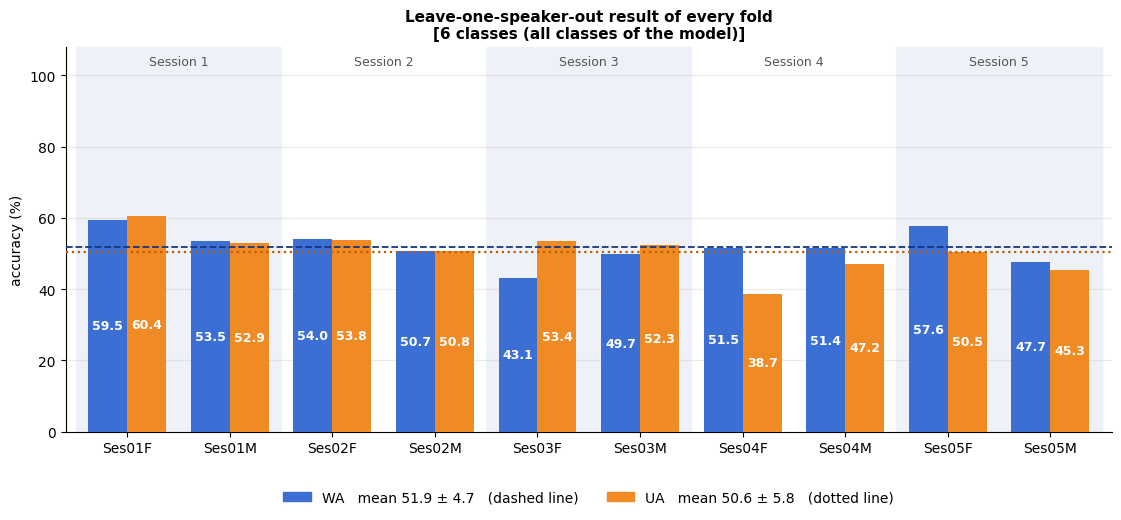

TABLE IV - performance statistics across 10 LOSO folds (mean, std, 95% CI)
Metric Mean (%) Std (%)     95% CI (%)
    WA    51.88   ±4.69 [48.52, 55.23]
    UA    50.55   ±5.81 [46.39, 54.71]



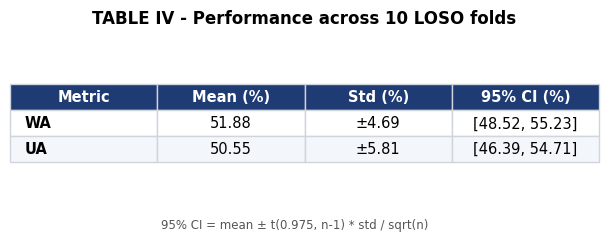

TABLE V - additional metrics (all held-out clips of all folds pooled)
              Metric Ours (%)
          F1 (macro)    46.93
       F1 (weighted)    53.46
   Precision (macro)    48.66
Precision (weighted)    56.50
      Recall (macro)    51.01
   Recall (weighted)    51.83



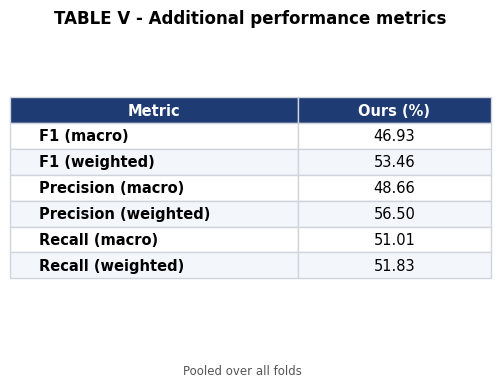

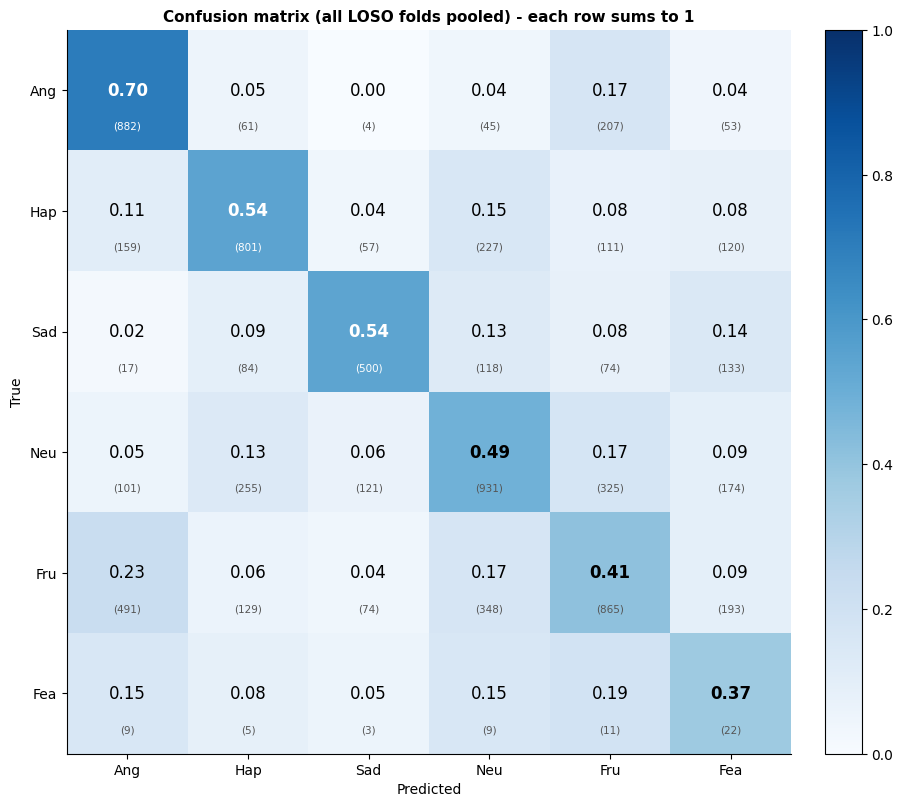

TABLE VI - per-class results (all folds pooled)
      Class Precision Recall F1-score  Support
      Anger      0.53   0.70     0.61     1252
  Happiness      0.60   0.54     0.57     1475
    Sadness      0.66   0.54     0.59      926
    Neutral      0.55   0.49     0.52     1907
Frustration      0.54   0.41     0.47     2100
       Fear      0.03   0.37     0.06       59



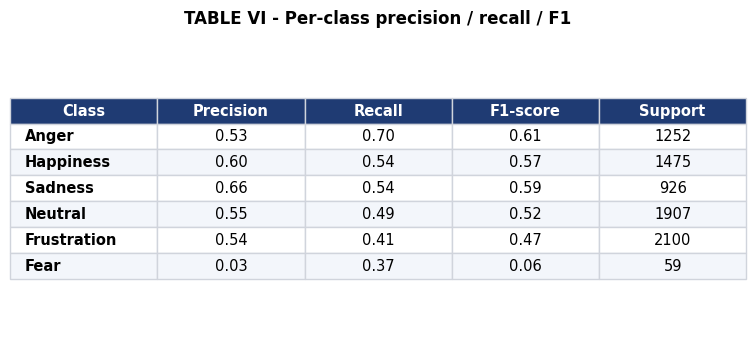

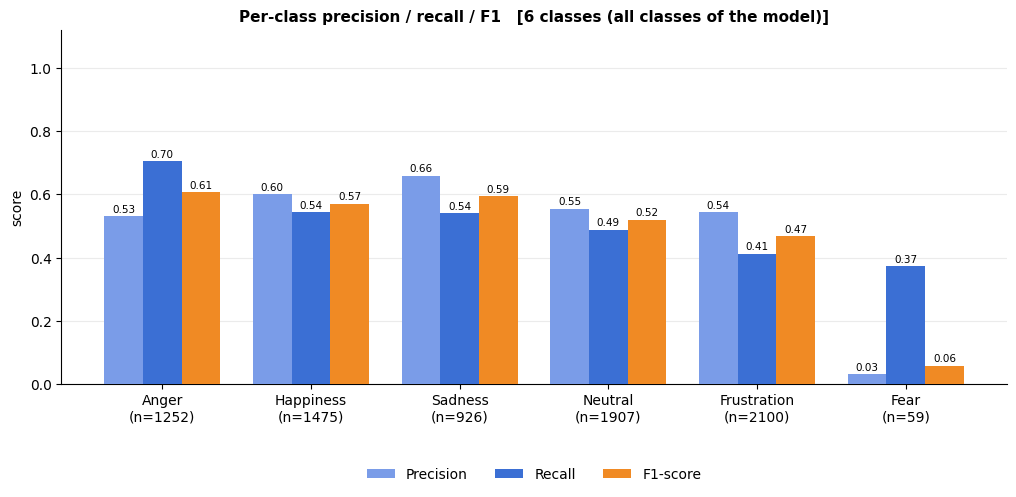

All tables / figures saved in /kaggle/working/final_eval


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

VIEWS = ["six"]        # "six" = all 6 classes of your model (anger, happiness, sadness, neutral, frustration, fear)  |  add "paper4" for the paper's 4-class view
SHORT = {"anger": "Ang", "happiness": "Hap", "sadness": "Sad", "neutral": "Neu", "frustration": "Fru", "fear": "Fea"}
PAPER = {"WA": (70.32, 3.02, "[68.16, 72.49]"), "UA": (71.30, 3.34, "[68.91, 73.69]"),     # paper, Table IV (IEMOCAP, 10 LOSO folds)
         "F1 (macro)": 70.78, "F1 (weighted)": 68.33, "Precision (macro)": 72.04,           # paper, Table V
         "Precision (weighted)": 70.97, "Recall (macro)": 71.59, "Recall (weighted)": 68.31}
C_WA, C_UA, C_HEAD = "#3b6fd4", "#f08a24", "#1f3b73"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

def view_data(fold, view):
    """clips of one fold -> (true, pred) in the chosen class view"""
    d = store[fold]; t, P, s = d["true"], d["probs"], d["split"]
    m = (s == "SA") if EVAL_SUBSET == "SA" else np.ones(len(t), bool)
    t, P = t[m], P[m]
    if view == "paper4":                       # paper: 4 classes. keep clips whose true class is one of them, decide among those 4 classes only
        k = t < 4; t, P = t[k], P[k][:, :4]
    return t, P.argmax(1)

def names_of(view): return [c for c in CLASS_NAMES][: (4 if view == "paper4" else NUM_CLASSES)]

def mean_std_ci(vals):
    v = np.asarray(vals, float); n = len(v); m = v.mean()
    if n < 2: return m, float("nan"), float("nan"), float("nan")
    sd = v.std(ddof=1); h = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
    return m, sd, m - h, m + h

def save_show(fig, name):
    fig.savefig(os.path.join(EVAL_DIR, name), dpi=160, bbox_inches="tight"); plt.show(); plt.close(fig)

def render_table(df, title, fname, widths=None, bold_first_col=True, subtitle=None):
    """draw a DataFrame as a clean table image (like the paper's tables) and show it"""
    nrow, ncol = df.shape
    fig, ax = plt.subplots(figsize=(max(6.2, 1.9 * ncol), 0.42 * (nrow + 1) + 0.9)); ax.axis("off")
    tb = ax.table(cellText=df.astype(str).values, colLabels=list(df.columns), loc="center", cellLoc="center", colWidths=widths)
    tb.auto_set_font_size(False); tb.set_fontsize(10.5); tb.scale(1, 1.55)
    for (r, c), cell in tb.get_celld().items():
        cell.set_edgecolor("#d0d4dc")
        if r == 0: cell.set_facecolor(C_HEAD); cell.set_text_props(color="white", fontweight="bold")
        else:
            cell.set_facecolor("#f3f6fb" if r % 2 == 0 else "white")
            if c == 0 and bold_first_col: cell.set_text_props(fontweight="bold"); cell.set_text_props(ha="left")
    ax.set_title(title, fontweight="bold", fontsize=12, pad=12)
    if subtitle: fig.text(0.5, 0.01, subtitle, ha="center", fontsize=8.5, color="#555555")
    save_show(fig, fname)

for VIEW in VIEWS:
    names = names_of(VIEW); K = len(names); tag = VIEW
    vname = "4 classes (Ang / Hap / Sad / Neu) - as in the paper" if VIEW == "paper4" else f"{K} classes (all classes of the model)"
    done = [f for f in folds if f in store]
    print("=" * 90); print(f"VIEW: {vname}   |   clips: {'clear (SA)' if EVAL_SUBSET == 'SA' else 'SA + SB'}   |   {len(done)} LOSO folds: {done}"); print("=" * 90)

    # ---------------- per-fold WA / UA ----------------
    rows = []
    for f in done:
        t, p = view_data(f, VIEW); wa, ua = wa_ua(t, p)
        rows.append({"Fold (held-out speaker)": f, "Clips": len(t), "WA (%)": round(wa, 2), "UA (%)": round(ua, 2)})
    df_fold = pd.DataFrame(rows); df_fold.to_csv(os.path.join(EVAL_DIR, f"{tag}_per_fold.csv"), index=False)

    # ================= FIGURE 1: WA & UA of every LOSO fold =================
    n = len(df_fold); fig, ax = plt.subplots(figsize=(max(8, 1.15 * n + 2), 5.0)); x = np.arange(n); w = 0.38
    for s_ in range((n + 1) // 2):                                   # one shaded block + label per session (2 speakers each)
        lo, hi = 2 * s_ - 0.5, min(2 * s_ + 1.5, n - 0.5)
        if s_ % 2 == 0: ax.axvspan(lo, hi, color="#eef1f7", zorder=0)
        ax.text((lo + hi) / 2, 103, f"Session {df_fold['Fold (held-out speaker)'].iloc[2 * s_][3:5].lstrip('0')}", ha="center", fontsize=9, color="#555555")
    b1 = ax.bar(x - w / 2, df_fold["WA (%)"], w, color=C_WA, label="WA", zorder=3); b2 = ax.bar(x + w / 2, df_fold["UA (%)"], w, color=C_UA, label="UA", zorder=3)
    for bars in (b1, b2):
        for r in bars: ax.text(r.get_x() + r.get_width() / 2, r.get_height() / 2, f"{r.get_height():.1f}", ha="center", va="center", fontsize=9, color="white", fontweight="bold", zorder=4)
    mw, sw = df_fold["WA (%)"].mean(), df_fold["WA (%)"].std(ddof=1) if n > 1 else 0
    mu, su = df_fold["UA (%)"].mean(), df_fold["UA (%)"].std(ddof=1) if n > 1 else 0
    ax.axhline(mw, color="#16367d", ls="--", lw=1.3, zorder=5); ax.axhline(mu, color="#b85d00", ls=":", lw=1.6, zorder=5)
    ax.legend(handles=[Patch(color=C_WA, label=f"WA   mean {mw:.1f} ± {sw:.1f}   (dashed line)"), Patch(color=C_UA, label=f"UA   mean {mu:.1f} ± {su:.1f}   (dotted line)")], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
    ax.set_xticks(x); ax.set_xticklabels(df_fold["Fold (held-out speaker)"]); ax.set_xlim(-0.6, n - 0.4); ax.set_ylim(0, 108); ax.set_yticks(range(0, 101, 20)); ax.set_ylabel("accuracy (%)")
    ax.set_title(f"Leave-one-speaker-out result of every fold\n[{vname}]", fontweight="bold", fontsize=11); ax.grid(axis="y", alpha=0.25, zorder=1)
    save_show(fig, f"{tag}_fig1_per_fold.png")

    # ================= TABLE IV: mean / std / 95% CI over the LOSO folds =================
    t4 = []
    for key, col in [("WA", "WA (%)"), ("UA", "UA (%)")]:
        m, sd, lo, hi = mean_std_ci(df_fold[col])
        row = {"Metric": key, "Mean (%)": f"{m:.2f}", "Std (%)": f"±{sd:.2f}" if sd == sd else "-", "95% CI (%)": f"[{lo:.2f}, {hi:.2f}]" if lo == lo else "-"}
        if VIEW == "paper4": pm, ps, pc = PAPER[key]; row.update({"Paper mean": f"{pm:.2f}", "Paper std": f"±{ps:.2f}", "Paper 95% CI": pc})
        t4.append(row)
    df_t4 = pd.DataFrame(t4); df_t4.to_csv(os.path.join(EVAL_DIR, f"{tag}_table_IV_mean_std_ci.csv"), index=False)
    print(f"TABLE IV - performance statistics across {len(done)} LOSO folds (mean, std, 95% CI)"); print(df_t4.to_string(index=False)); print()
    render_table(df_t4, f"TABLE IV - Performance across {len(done)} LOSO folds", f"{tag}_table_IV.png",
                 subtitle="95% CI = mean ± t(0.975, n-1) * std / sqrt(n).   Paper columns: Gan et al., IEEE TAFFC 2026, Table IV." if VIEW == "paper4" else "95% CI = mean ± t(0.975, n-1) * std / sqrt(n)")

    # ================= TABLE V: macro / weighted precision, recall, F1 (all folds pooled) =================
    T = np.concatenate([view_data(f, VIEW)[0] for f in done]); P = np.concatenate([view_data(f, VIEW)[1] for f in done])
    pr, rc, f1, sup = precision_recall_fscore_support(T, P, labels=list(range(K)), zero_division=0)
    pres = [c for c in range(K) if sup[c] > 0]
    def avg(kind):
        a = precision_recall_fscore_support(T, P, labels=pres, average=kind, zero_division=0); return [a[0] * 100, a[1] * 100, a[2] * 100]
    ma, we = avg("macro"), avg("weighted")
    v = {"F1 (macro)": ma[2], "F1 (weighted)": we[2], "Precision (macro)": ma[0], "Precision (weighted)": we[0], "Recall (macro)": ma[1], "Recall (weighted)": we[1]}
    t5 = [{"Metric": k, "Ours (%)": f"{x:.2f}", **({"Paper (%)": f"{PAPER[k]:.2f}"} if VIEW == "paper4" else {})} for k, x in v.items()]
    df_t5 = pd.DataFrame(t5); df_t5.to_csv(os.path.join(EVAL_DIR, f"{tag}_table_V_f1_precision_recall.csv"), index=False)
    print("TABLE V - additional metrics (all held-out clips of all folds pooled)"); print(df_t5.to_string(index=False)); print()
    render_table(df_t5, "TABLE V - Additional performance metrics", f"{tag}_table_V.png", widths=[0.5, 0.25, 0.25][: df_t5.shape[1]] if VIEW == "paper4" else [0.6, 0.4],
                 subtitle="Pooled over all folds.   Paper column: Gan et al., IEEE TAFFC 2026, Table V." if VIEW == "paper4" else "Pooled over all folds")

    # ================= FIGURE 2: confusion matrix (paper Fig. 5 style) =================
    CM_FOLD = None      # None = all folds pooled; or e.g. "Ses01F" to draw a single LOSO fold like the paper's Fig. 5
    t_, p_ = (T, P) if CM_FOLD is None else view_data(CM_FOLD, VIEW)
    cm = confusion_matrix(t_, p_, labels=list(range(K))); norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(1.35 * K + 3, 1.2 * K + 2.2)); im = ax.imshow(norm, vmin=0, vmax=1, cmap="Blues"); ax.grid(False)
    ax.set_xticks(range(K)); ax.set_xticklabels([SHORT[n] for n in names]); ax.set_yticks(range(K)); ax.set_yticklabels([SHORT[n] for n in names])
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", fontsize=12, fontweight="bold" if i == j else "normal", color="white" if norm[i, j] > 0.5 else "black")
            ax.text(j, i + 0.30, f"({cm[i, j]})", ha="center", va="center", fontsize=7.5, color="white" if norm[i, j] > 0.5 else "#555555")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); fig.colorbar(im, fraction=0.046, pad=0.04)
    ax.set_title(f"Confusion matrix ({'all LOSO folds pooled' if CM_FOLD is None else CM_FOLD}) - each row sums to 1", fontweight="bold", fontsize=11)
    save_show(fig, f"{tag}_fig2_confusion_matrix.png")

    # ================= TABLE VI + FIGURE 3: per-class precision / recall / F1 / support =================
    df_cls = pd.DataFrame({"Class": [n.capitalize() for n in names], "Precision": pr, "Recall": rc, "F1-score": f1, "Support": sup.astype(int)})
    df_cls.to_csv(os.path.join(EVAL_DIR, f"{tag}_table_VI_per_class.csv"), index=False)
    print("TABLE VI - per-class results (all folds pooled)"); print(df_cls.to_string(index=False, formatters={k: "{:.2f}".format for k in ["Precision", "Recall", "F1-score"]})); print()
    render_table(df_cls.assign(**{k: df_cls[k].map("{:.2f}".format) for k in ["Precision", "Recall", "F1-score"]}), "TABLE VI - Per-class precision / recall / F1", f"{tag}_table_VI.png")
    fig, ax = plt.subplots(figsize=(max(7, 1.7 * K + 2), 4.6)); x = np.arange(K); w = 0.26
    for k, (arr, col, lab) in enumerate([(pr, "#7a9ce8", "Precision"), (rc, C_WA, "Recall"), (f1, C_UA, "F1-score")]):
        bars = ax.bar(x + (k - 1) * w, arr, w, color=col, label=lab, zorder=3)
        for r in bars: ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.012, f"{r.get_height():.2f}", ha="center", fontsize=7.5)
    ax.set_xticks(x); ax.set_xticklabels([f"{n.capitalize()}\n(n={s})" for n, s in zip(names, sup)]); ax.set_ylim(0, 1.12); ax.set_ylabel("score")
    ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2)); ax.grid(axis="y", alpha=0.25, zorder=1)
    ax.set_title(f"Per-class precision / recall / F1   [{vname}]", fontweight="bold", fontsize=11)
    save_show(fig, f"{tag}_fig3_per_class.png")

    json.dump({"view": VIEW, "subset": EVAL_SUBSET, "folds": done, "per_fold": df_fold.to_dict("records"), "table_IV": df_t4.to_dict("records"),
               "table_V": df_t5.to_dict("records"), "per_class": df_cls.to_dict("records"), "confusion_matrix": cm.tolist()},
              open(os.path.join(EVAL_DIR, f"{tag}_results.json"), "w"), indent=1)
print("All tables / figures saved in", EVAL_DIR)